In [32]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

# Expected location based on the supplied app.py
DATA_PATH = Path("data/train-test.csv")
if not DATA_PATH.exists():
    # Also support running the notebook beside the CSV.
    DATA_PATH = Path("train-test.csv")

RANDOM_STATE = 42
print("Notebook working directory:", Path.cwd())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset exists:", DATA_PATH.exists())


Notebook working directory: /home/dheeraj/Development/AI-ML/Assessment
Dataset path: /home/dheeraj/Development/AI-ML/Assessment/data/train-test.csv
Dataset exists: True


In [33]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Training CSV not found. Place the project dataset at "
        "'data/train-test.csv' (or 'train-test.csv' beside this notebook), "
        "then rerun this cell."
    )

df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
display(df.head())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_count": df.nunique(dropna=False)
}).sort_values("missing_pct", ascending=False))


Rows: 48,000 | Columns: 14


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


,dtype,missing_count,missing_pct,unique_count
market_index,float64,374,0.78,32885
weight,float64,300,0.62,23679
delivery,object,0,0.00,64
pickup_lat,float64,0,0.00,64
load_id,object,0,0.00,48000
pickup,object,0,0.00,64
delivery_lat,float64,0,0.00,64
pickup_lon,float64,0,0.00,63
distance,float64,0,0.00,21204
delivery_lon,float64,0,0.00,63


In [34]:
print("Duplicate rows:", int(df.duplicated().sum()))

date_candidates = [c for c in df.columns if c.lower() in {"date", "pickup_date", "load_date", "pickup_datetime"}]
DATE_COL = date_candidates[0] if date_candidates else None
if DATE_COL:
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
    print(f"Parsed date column: {DATE_COL}")
    print("Unparseable dates:", int(df[DATE_COL].isna().sum()))
    print("Date range:", df[DATE_COL].min(), "to", df[DATE_COL].max())

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    display(df[numeric_cols].describe().T)


Duplicate rows: 0
Parsed date column: date
Unparseable dates: 0
Date range: 2025-01-01 00:00:00 to 2025-10-31 00:00:00


,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [35]:
target_candidates = [
    "posted_rate", "rate", "freight_rate", "target", "price", "load_rate",
    "posted rate", "rate_usd"
]
lower_to_original = {c.lower(): c for c in df.columns}
TARGET = next((lower_to_original[name] for name in target_candidates if name in lower_to_original), None)

if TARGET is None:
    raise ValueError(
        "Could not infer the target column. Set TARGET manually to the column "
        "containing the actual posted freight rate. Available columns: "
        + ", ".join(map(str, df.columns))
    )

print("Selected target:", TARGET)
display(df[TARGET].describe().to_frame("target_summary"))


Selected target: posted_rate


,target_summary
count,48000.000000
mean,2373.980682
std,1486.493245
min,57.220000
25%,1251.555000
50%,2030.760000
75%,3330.750000
max,25533.000000


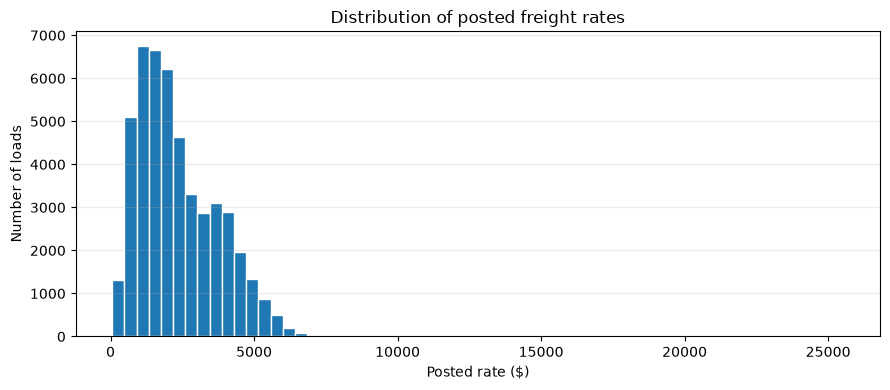

Target missing: 0
Target <= 0: 0
Target skewness: 1.902


In [36]:
# Target distribution
target = pd.to_numeric(df[TARGET], errors="coerce")
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(target.dropna(), bins=60, edgecolor="white")
ax.set(title="Distribution of posted freight rates", xlabel="Posted rate ($)", ylabel="Number of loads")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("Target missing:", int(target.isna().sum()))
print("Target <= 0:", int((target <= 0).sum()))
print("Target skewness:", round(float(target.skew()), 3))


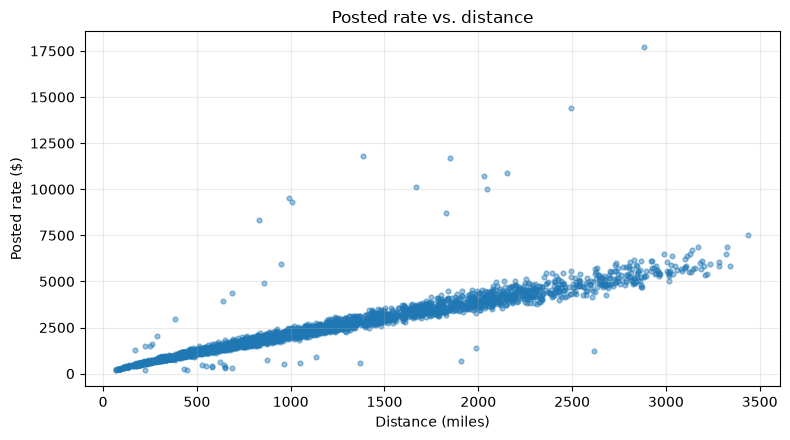

In [37]:
# Distance vs. rate
distance_col = lower_to_original.get("distance")
if distance_col:
    plot_df = df[[distance_col, TARGET]].copy()
    plot_df[distance_col] = pd.to_numeric(plot_df[distance_col], errors="coerce")
    plot_df[TARGET] = pd.to_numeric(plot_df[TARGET], errors="coerce")
    plot_df = plot_df.dropna()
    if len(plot_df) > 3000:
        plot_df = plot_df.sample(3000, random_state=RANDOM_STATE)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.scatter(plot_df[distance_col], plot_df[TARGET], s=12, alpha=0.45)
    ax.set(title="Posted rate vs. distance", xlabel="Distance (miles)", ylabel="Posted rate ($)")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Skipped distance plot: no 'distance' column found.")


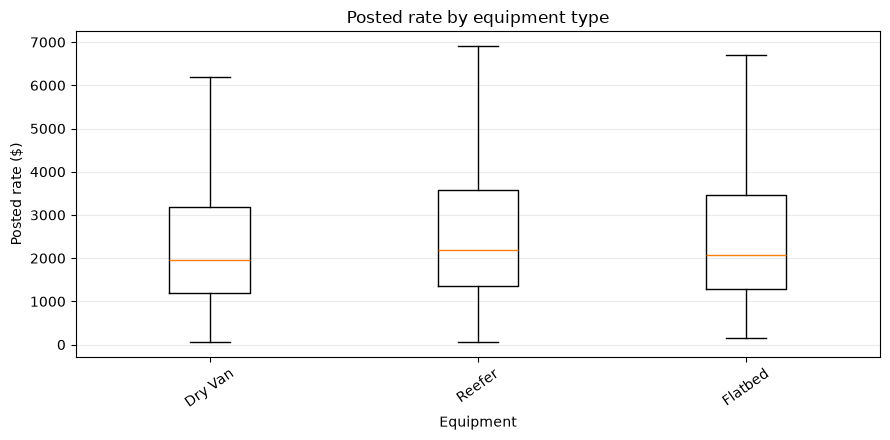

In [38]:
# Rate by equipment
equipment_col = lower_to_original.get("equipment")
if equipment_col:
    box_df = df[[equipment_col, TARGET]].copy()
    box_df[TARGET] = pd.to_numeric(box_df[TARGET], errors="coerce")
    box_df = box_df.dropna()
    top_equipment = box_df[equipment_col].value_counts().head(12).index
    box_df = box_df[box_df[equipment_col].isin(top_equipment)]
    groups = [box_df.loc[box_df[equipment_col] == name, TARGET].values for name in top_equipment]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.boxplot(groups, tick_labels=[str(x) for x in top_equipment], showfliers=False)
    ax.set(title="Posted rate by equipment type", xlabel="Equipment", ylabel="Posted rate ($)")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Skipped equipment plot: no 'equipment' column found.")


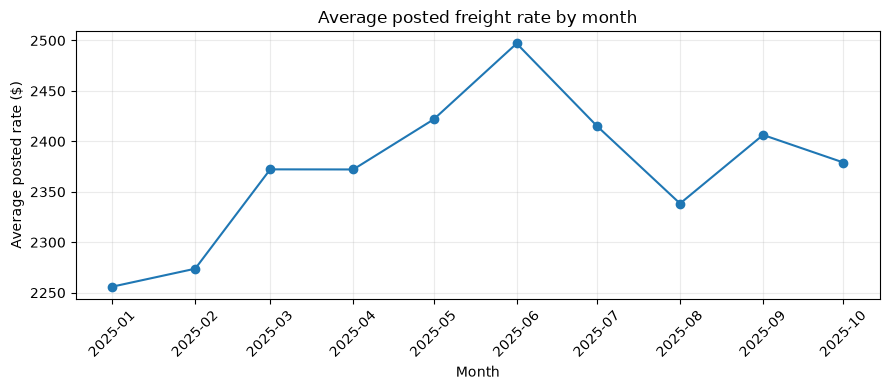

,average_rate
date,
2025-01-01,2255.967048
2025-02-01,2273.804801
2025-03-01,2372.268092
2025-04-01,2372.162308
2025-05-01,2421.776342
2025-06-01,2497.030115
2025-07-01,2415.162030
2025-08-01,2338.407661
2025-09-01,2406.374013


In [39]:
# Monthly trend
if DATE_COL:
    trend = df.assign(_target=pd.to_numeric(df[TARGET], errors="coerce")).dropna(subset=[DATE_COL, "_target"])
    monthly = trend.set_index(DATE_COL)["_target"].resample("MS").mean()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(monthly.index, monthly.values, marker="o")
    ax.set(title="Average posted freight rate by month", xlabel="Month", ylabel="Average posted rate ($)")
    ax.grid(alpha=0.25)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    display(monthly.rename("average_rate").to_frame())
else:
    print("Skipped monthly trend: no recognized date column found.")


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_validate

work = df.copy()
work[TARGET] = pd.to_numeric(work[TARGET], errors="coerce")
work = work.dropna(subset=[TARGET]).copy()

# Use the date for ordering and derive useful calendar features.
if DATE_COL:
    work[DATE_COL] = pd.to_datetime(work[DATE_COL], errors="coerce")
    work["pickup_year"] = work[DATE_COL].dt.year
    work["pickup_month"] = work[DATE_COL].dt.month
    work["pickup_dayofweek"] = work[DATE_COL].dt.dayofweek
    work["pickup_day"] = work[DATE_COL].dt.day

# Avoid obvious identifier leakage.
id_cols = [c for c in work.columns if c.lower() in {"id", "load_id", "loadid", "row_id"}]
drop_cols = [TARGET] + id_cols
if DATE_COL:
    drop_cols.append(DATE_COL)

X = work.drop(columns=list(dict.fromkeys(drop_cols)), errors="ignore")
y = work[TARGET].astype(float)

# Keep only positive targets for log1p-based rate modelling.
positive_mask = y > 0
X = X.loc[positive_mask].copy()
y = y.loc[positive_mask].copy()

# Convert numeric-looking columns only when already numeric; categorical columns remain categorical.
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print(f"Rows retained for modelling: {len(X):,}")
print(f"Numeric features ({len(numeric_features)}):", numeric_features)
print(f"Categorical features ({len(categorical_features)}):", categorical_features)


Rows retained for modelling: 48,000
Numeric features (12): ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'pickup_year', 'pickup_month', 'pickup_dayofweek', 'pickup_day']
Categorical features (3): ['pickup', 'delivery', 'equipment']


In [41]:
if DATE_COL:
    order = work.loc[X.index, DATE_COL].sort_values(kind="stable").index
    X = X.loc[order]
    y = y.loc[order]

split_at = int(len(X) * 0.8)
if split_at < 1 or split_at >= len(X):
    raise ValueError("Not enough rows to create a train/validation split.")

X_train, X_valid = X.iloc[:split_at].copy(), X.iloc[split_at:].copy()
y_train, y_valid = y.iloc[:split_at].copy(), y.iloc[split_at:].copy()

print(f"Training rows: {len(X_train):,}")
print(f"Validation rows: {len(X_valid):,}")
if DATE_COL:
    print("Training period:", work.loc[X_train.index, DATE_COL].min(), "to", work.loc[X_train.index, DATE_COL].max())
    print("Validation period:", work.loc[X_valid.index, DATE_COL].min(), "to", work.loc[X_valid.index, DATE_COL].max())


Training rows: 38,400
Validation rows: 9,600
Training period: 2025-01-01 00:00:00 to 2025-08-31 00:00:00
Validation period: 2025-08-31 00:00:00 to 2025-10-31 00:00:00


In [42]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features),
], remainder="drop", verbose_feature_names_out=False)

model = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=250,
    max_leaf_nodes=31,
    l2_regularization=0.1,
    random_state=RANDOM_STATE,
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model),
])

pipeline.fit(X_train, np.log1p(y_train))
pred_valid = np.expm1(pipeline.predict(X_valid))
pred_valid = np.clip(pred_valid, 1.0, None)


In [43]:
mae = mean_absolute_error(y_valid, pred_valid)
rmse = mean_squared_error(y_valid, pred_valid) ** 0.5
r2 = r2_score(y_valid, pred_valid)

metrics = pd.DataFrame({
    "Metric": ["MAE ($)", "RMSE ($)", "R²"],
    "Value": [mae, rmse, r2],
})
display(metrics.style.format({"Value": "{:,.4f}"}))
print(f"Validation MAE: ${mae:,.2f}")
print(f"Validation RMSE: ${rmse:,.2f}")
print(f"Validation R²: {r2:.4f}")


,Metric,Value
0,MAE ($),120.5732
1,RMSE ($),636.3354
2,R²,0.8259


Validation MAE: $120.57
Validation RMSE: $636.34
Validation R²: 0.8259


,actual_rate,predicted_rate,residual
38400,631.07,648.681952,-17.611952
38401,1755.35,1774.456304,-19.106304
38402,4466.13,4541.165360,-75.035360
38403,2574.99,2598.471005,-23.481005
38404,576.69,554.600325,22.089675
38405,3685.33,3562.281784,123.048216
38406,2851.40,2882.519201,-31.119201
38407,2996.08,2969.905326,26.174674
38408,4225.72,4290.197369,-64.477369
38409,3850.74,3779.812995,70.927005


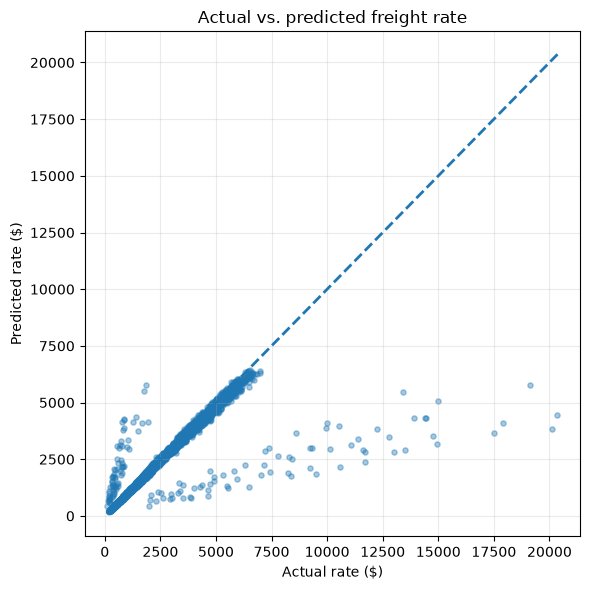

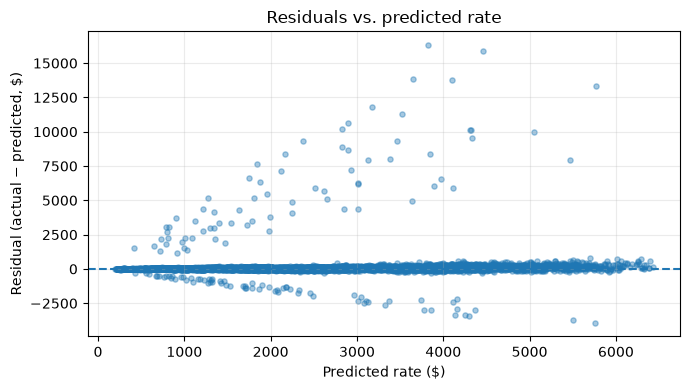

In [44]:
results = pd.DataFrame({
    "actual_rate": y_valid,
    "predicted_rate": pred_valid,
})
results["residual"] = results["actual_rate"] - results["predicted_rate"]
display(results.head(10))

lo = min(results["actual_rate"].min(), results["predicted_rate"].min())
hi = max(results["actual_rate"].max(), results["predicted_rate"].max())
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(results["actual_rate"], results["predicted_rate"], s=14, alpha=0.4)
ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=2)
ax.set(title="Actual vs. predicted freight rate", xlabel="Actual rate ($)", ylabel="Predicted rate ($)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(results["predicted_rate"], results["residual"], s=14, alpha=0.4)
ax.axhline(0, linestyle="--", linewidth=1.5)
ax.set(title="Residuals vs. predicted rate", xlabel="Predicted rate ($)", ylabel="Residual (actual − predicted, $)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


,fold,train_rows,validation_rows,MAE,RMSE,R2
0,1,6400,6400,136.047831,531.834235,0.858139
1,2,12800,6400,218.515244,562.952449,0.851526
2,3,19200,6400,121.728870,552.637091,0.862469
3,4,25600,6400,126.998313,688.761812,0.805895
4,5,32000,6400,125.181766,653.473974,0.811361


,mean,std
MAE,145.694405,41.050548
RMSE,597.931912,68.882287
R2,0.837878,0.027053


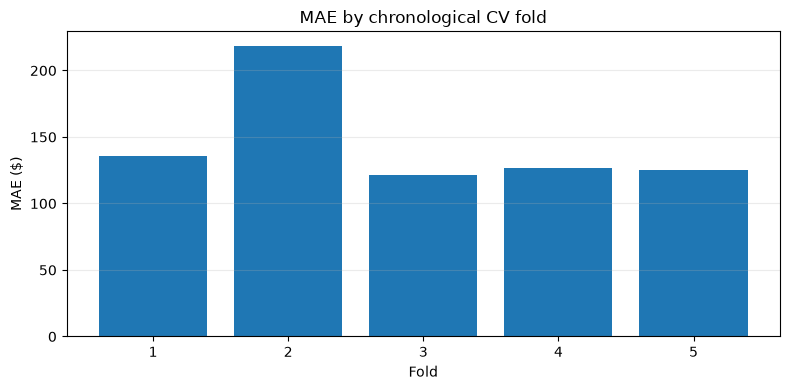

In [45]:
n_splits = min(5, max(2, len(X_train) // 1000))
if len(X_train) > n_splits:
    tscv = TimeSeriesSplit(n_splits=n_splits)
    fold_rows = []
    for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_train), start=1):
        fold_pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("model", HistGradientBoostingRegressor(
                learning_rate=0.08, max_iter=250, max_leaf_nodes=31,
                l2_regularization=0.1, random_state=RANDOM_STATE
            )),
        ])
        y_fold_train = y_train.iloc[tr_idx]
        y_fold_valid = y_train.iloc[va_idx]
        fold_pipe.fit(X_train.iloc[tr_idx], np.log1p(y_fold_train))
        fold_pred = np.clip(np.expm1(fold_pipe.predict(X_train.iloc[va_idx])), 1.0, None)
        fold_rows.append({
            "fold": fold,
            "train_rows": len(tr_idx),
            "validation_rows": len(va_idx),
            "MAE": mean_absolute_error(y_fold_valid, fold_pred),
            "RMSE": mean_squared_error(y_fold_valid, fold_pred) ** 0.5,
            "R2": r2_score(y_fold_valid, fold_pred),
        })
    cv_results = pd.DataFrame(fold_rows)
    display(cv_results)
    display(cv_results[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).T)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(cv_results["fold"].astype(str), cv_results["MAE"])
    ax.set(title="MAE by chronological CV fold", xlabel="Fold", ylabel="MAE ($)")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Insufficient training rows for time-series cross-validation.")


In [46]:
output_dir = Path("notebook_outputs")
output_dir.mkdir(exist_ok=True)

results.reset_index(drop=True).to_csv(output_dir / "validation_predictions.csv", index=False)
metrics.to_csv(output_dir / "validation_metrics.csv", index=False)

import joblib
joblib.dump({
    "pipeline": pipeline,
    "target_column": TARGET,
    "date_column": DATE_COL,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target_transform": "log1p",
}, output_dir / "freight_rate_baseline.joblib")

print("Saved files:")
for path in sorted(output_dir.iterdir()):
    print(f"- {path} ({path.stat().st_size:,} bytes)")


Saved files:
- notebook_outputs/freight_rate_baseline.joblib (377,202 bytes)
- notebook_outputs/validation_metrics.csv (90 bytes)
- notebook_outputs/validation_predictions.csv (430,266 bytes)
